# Airbnb Decision Support System (DSS)


This notebook presents a Decision Support System (DSS) for Airbnb hosts, providing price predictions and time series forecasting to optimize pricing and maximize revenue.

In [1]:
#import libraries
import numpy as np
import pandas as pd
import seaborn as sns

# EDA

## Data Cleaning

In [2]:
data = pd.read_csv("AB_NYC_2019.csv")
data

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [3]:
data.isnull().sum()

id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [4]:
data = data.dropna(subset=["name", "host_name"])
data.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10037
reviews_per_month                 10037
calculated_host_listings_count        0
availability_365                      0
dtype: int64

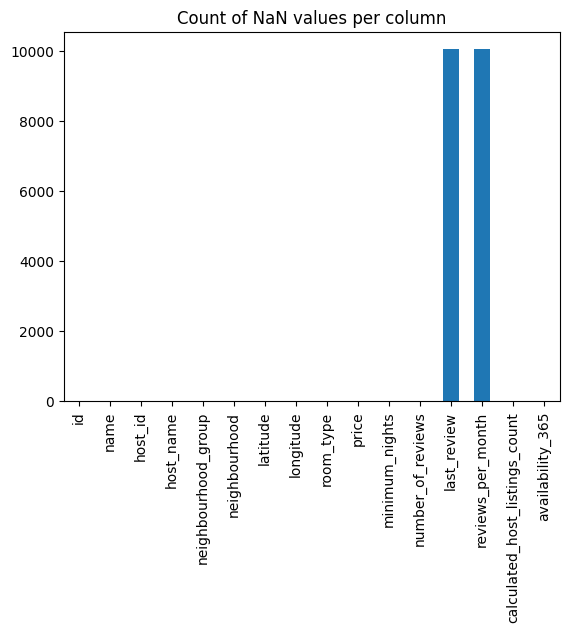

In [5]:
import matplotlib.pyplot as plt

data.isnull().sum().plot(kind="bar", title="Count of NaN values per column")
plt.show()


In [6]:
data.shape

(48858, 16)

In [7]:
data.loc[:,"reviews_per_month"] = data["reviews_per_month"].fillna(data["reviews_per_month"].mean())  # Fill with mean
data["reviews_per_month"].isnull().sum()

np.int64(0)

In [8]:
data.isnull().sum()

id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10037
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64

In [9]:
data.loc[:,"last_review"].dtype

dtype('O')

In [10]:
# Convert the column to datetime
data["last_review"] = pd.to_datetime(data["last_review"], errors="coerce")

# Fill missing values with the most frequent date (mode)
mode_date = data["last_review"].mode()[0]
data["last_review"] = data["last_review"].fillna(mode_date)

/var/folders/n8/jdzrgr4j31x6sg9scrpqr01w0000gn/T/ipykernel_18141/2707370671.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["last_review"] = pd.to_datetime(data["last_review"], errors="coerce")
/var/folders/n8/jdzrgr4j31x6sg9scrpqr01w0000gn/T/ipykernel_18141/2707370671.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["last_review"] = data["last_review"].fillna(mode_date)


In [11]:
data["last_review"].isnull().sum()

np.int64(0)

In [12]:
data.isnull().sum()

id                                0
name                              0
host_id                           0
host_name                         0
neighbourhood_group               0
neighbourhood                     0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
last_review                       0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64

### **Key Insights from Data Cleaning**

 **1. General Dataset Overview**
- The dataset contains **48,895 rows** and **16 columns**.
- No **duplicate rows** were found.
- Data types consist of:
  - **Numerical columns:** `int64`, `float64`
  - **Categorical columns:** `object` (text-based features)

---

 **2. Missing Values Analysis**
- **Total missing values:** **20,141**
- Columns with missing values:
  - **`name`**: **16 missing**
  - **`host_name`**: **21 missing**
  - **`last_review`**: **10,052 missing** (likely because some listings never received reviews)
  - **`reviews_per_month`**: **10,052 missing** (corresponds with `last_review`)

---

## Univariate Analysis

Analyze single variables to understand their distributions.

**a. Numerical Features**

Summary statistics:



In [13]:
data.describe()


,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.885800e+04,4.885800e+04,48858.000000,48858.000000,48858.000000,48858.000000,48858.000000,48858,48858.000000,48858.000000,48858.000000
mean,1.902335e+07,6.763169e+07,40.728941,-73.952170,152.740309,7.012444,23.273098,2018-11-27 01:38:01.665234176,1.373229,7.148369,112.801425
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,2011-03-28 00:00:00,0.010000,1.000000,0.000000
25%,9.475980e+06,7.818669e+06,40.690090,-73.983070,69.000000,1.000000,1.000000,2018-11-04 00:00:00,0.280000,1.000000,0.000000
50%,1.969114e+07,3.079133e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,2019-06-14 00:00:00,1.220000,1.000000,45.000000
75%,2.915765e+07,1.074344e+08,40.763107,-73.936280,175.000000,5.000000,24.000000,2019-06-23 00:00:00,1.580000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,2019-07-08 00:00:00,58.500000,327.000000,365.000000
std,1.098289e+07,7.862389e+07,0.054528,0.046159,240.232386,20.019757,44.549898,NaN,1.497816,32.964600,131.610962


Scatter to visualize outliers:

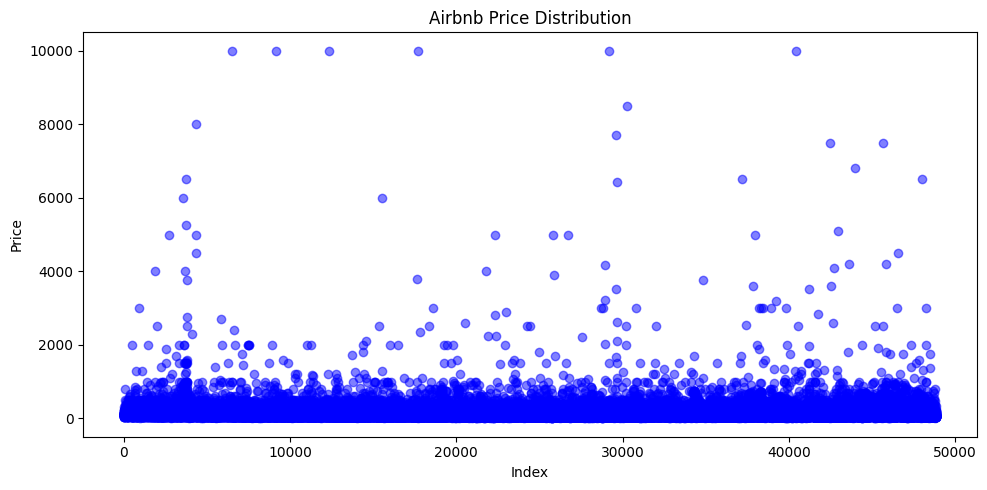

In [14]:
import matplotlib.pyplot as plt
# Scatter plot for price distribution
plt.figure(figsize=(10, 5))
plt.scatter(range(len(data)), data['price'], alpha=0.5, color='blue')
plt.xlabel('Index')
plt.ylabel('Price')
plt.title('Airbnb Price Distribution')
plt.tight_layout()
plt.show()


 📊 **Interpretation of the Airbnb Price Distribution Scatter Plot**  

 The scatter plot shows **Airbnb price distribution**, with most listings priced under **$500** but some extreme outliers exceeding **$10,000**. The distribution is **heavily skewed**, suggesting a few luxury or mispriced listings. Prices are scattered across the dataset with no strong pattern. Most listings fall within a predictable range, while outliers may need separate analysis. **Hosts should focus on market trends rather than outliers when pricing listings.** A **log transformation** could help normalize the data for better analysis.


**b. Categorical Features**

Check unique values:



In [15]:
data.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [16]:
data['neighbourhood_group'].value_counts()


neighbourhood_group
Manhattan        21643
Brooklyn         20089
Queens            5664
Bronx             1089
Staten Island      373
Name: count, dtype: int64

Visualize with bar plots:

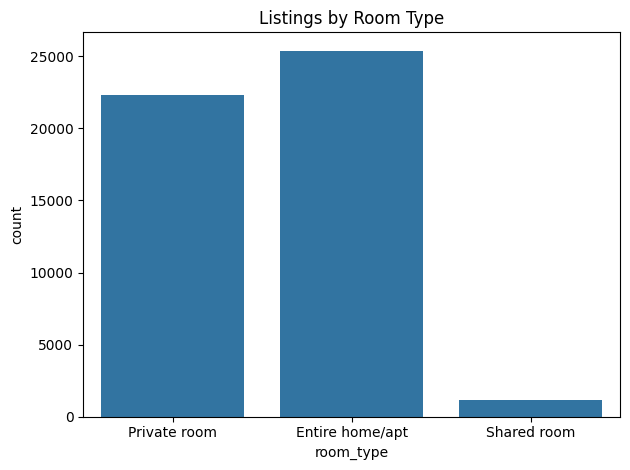

In [17]:
sns.countplot(x=data['room_type'])
plt.title('Listings by Room Type')
plt.tight_layout()
plt.show()


The bar chart shows the distribution of Airbnb listings by room type. **Entire homes/apartments** are the most common, followed by **private rooms**, while **shared rooms** are the least frequent. This suggests that travelers prefer privacy, with entire homes being the top choice. Private rooms remain popular, likely due to affordability. Shared rooms have low demand, possibly appealing to budget travelers. For hosts, listing an **entire home** offers the highest market exposure, while private rooms are also a strong option. Shared rooms may require competitive pricing to attract guests.

## Bivariate & Multivariate Analysis

Analyze relationships between variables.

**a. Price Analysis**

Price distribution per neighborhood:



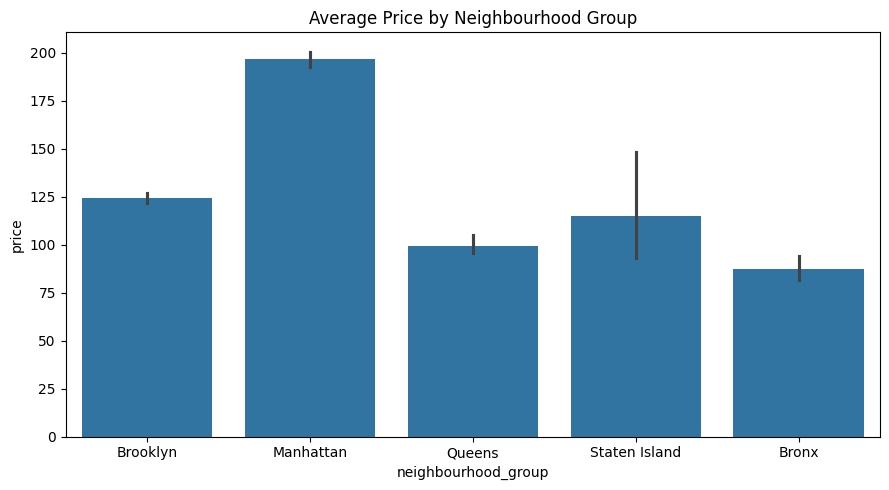

In [18]:
plt.figure(figsize=(9, 5))
sns.barplot(x='neighbourhood_group', y='price', data=data)
plt.title('Average Price by Neighbourhood Group')
plt.tight_layout()
plt.show()


This bar chart compares the average price of listings across different neighborhood groups in New York City. Manhattan has the highest average price, followed by Brooklyn and Staten Island, while Queens and the Bronx have lower prices. The error bars indicate the variability in pricing, with Staten Island showing the highest variation.

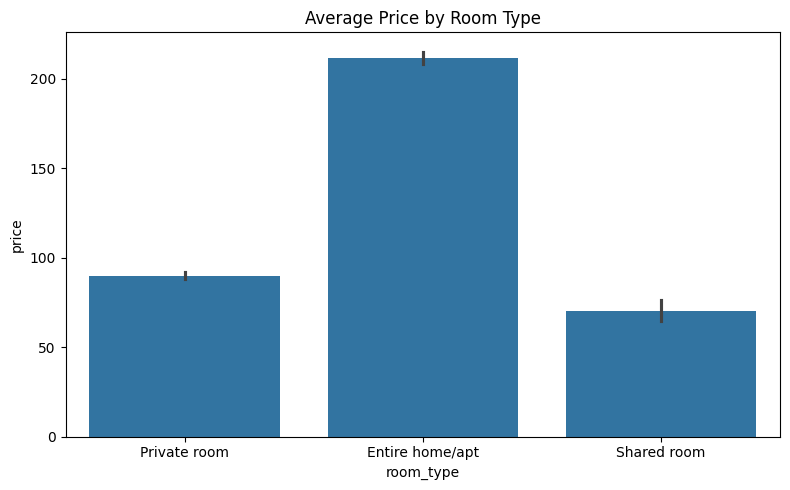

In [19]:
plt.figure(figsize=(8, 5))
sns.barplot(x='room_type', y='price', data=data)
plt.title('Average Price by Room Type')
plt.tight_layout()
plt.show()


This bar chart compares the average price of different room types. Entire homes/apartments have the highest average price, followed by private rooms, while shared rooms are the cheapest. The error bars indicate variability, with entire homes having the least uncertainty and shared rooms showing slightly more variation.

**b. Correlations**

Check correlation matrix:

In [20]:
import pandas as pd

# Convert 'last_review' to a proper datetime format instead of dropping it
data_temp = data.drop(columns=['name', 'host_name', 'neighbourhood'])
data_temp['last_review'] = pd.to_datetime(data['last_review'])

# Encode categorical columns but KEEP 'neighbourhood_group' and 'last_review'
categorical_cols = ['room_type','neighbourhood_group', ]  # Specify categorical columns to encode
data_encoded = pd.get_dummies(data_temp, columns=categorical_cols, drop_first=True)

print(data_encoded.info())


<class 'pandas.core.frame.DataFrame'>
Index: 48858 entries, 0 to 48894
Data columns (total 17 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   id                                 48858 non-null  int64         
 1   host_id                            48858 non-null  int64         
 2   latitude                           48858 non-null  float64       
 3   longitude                          48858 non-null  float64       
 4   price                              48858 non-null  int64         
 5   minimum_nights                     48858 non-null  int64         
 6   number_of_reviews                  48858 non-null  int64         
 7   last_review                        48858 non-null  datetime64[ns]
 8   reviews_per_month                  48858 non-null  float64       
 9   calculated_host_listings_count     48858 non-null  int64         
 10  availability_365                   4885

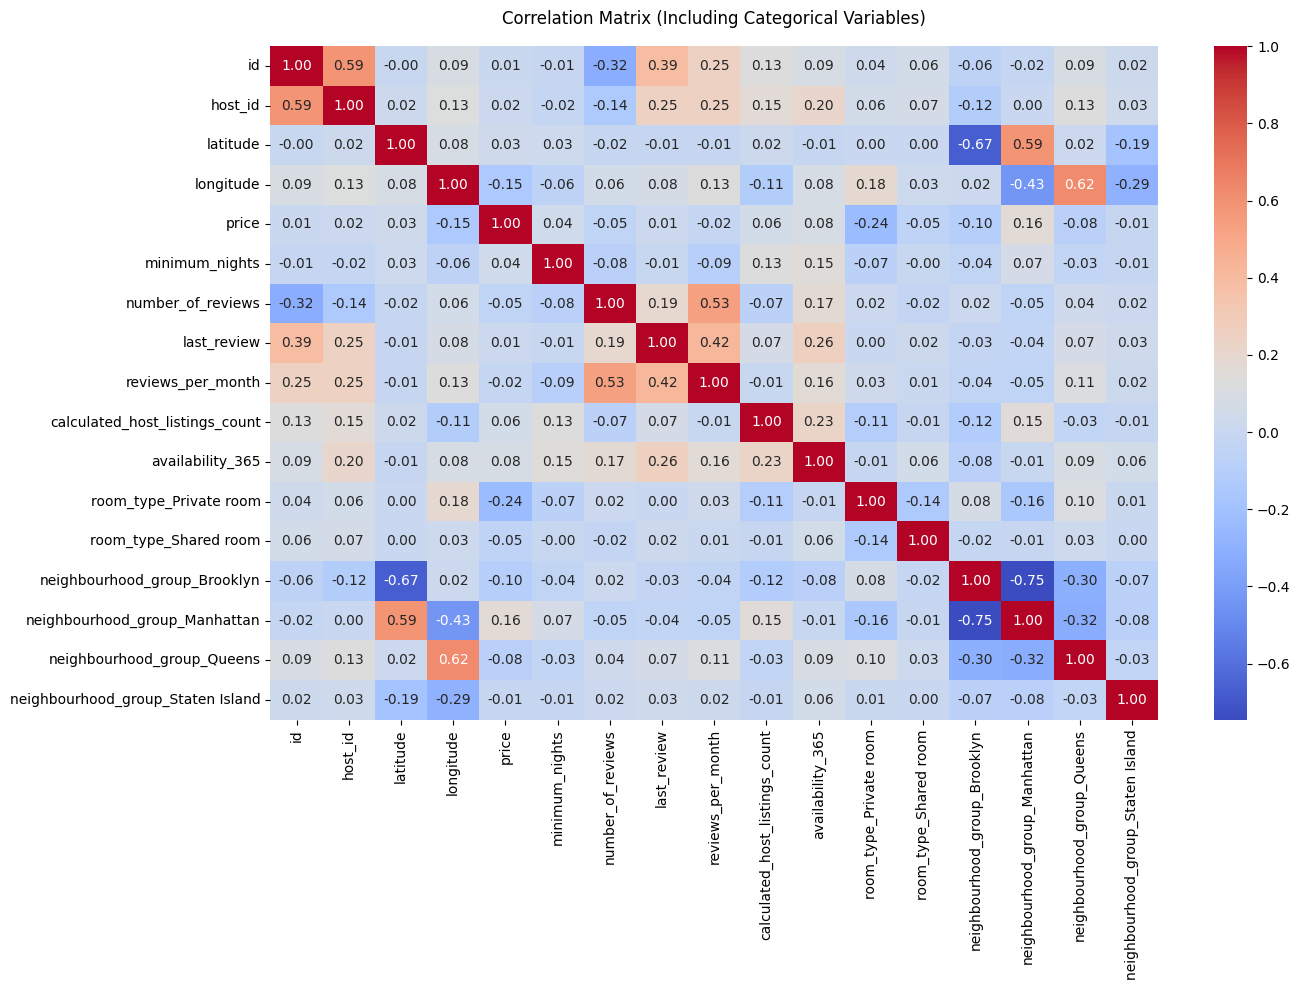

In [21]:
#Heatmap:
plt.figure(figsize=(14, 10))
sns.heatmap(data_encoded.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix (Including Categorical Variables)", pad=16)
plt.tight_layout()
plt.show()


With respect to **price**, the correlation matrix shows the following insights:  

- **Price has a weak correlation with most variables**, meaning no single feature strongly predicts price.  
- **Neighbourhood Group (Manhattan) has a slight positive correlation (~0.16)**, indicating prices tend to be higher in Manhattan.  
- **Room Type (Entire Home/Apt) likely has a positive correlation with price**, though it is not explicitly shown in the matrix. Private and shared rooms generally have negative or weak correlations.  
- **Minimum Nights has a weak negative correlation (~-0.15)**, suggesting that longer minimum stays slightly lower the price.  
- **Other features like number of reviews and availability show little to no impact on price.**  

Overall, price is primarily influenced by location and room type, with other variables playing a minor role.

**c. Availability & Price Relationship**

Line plot:

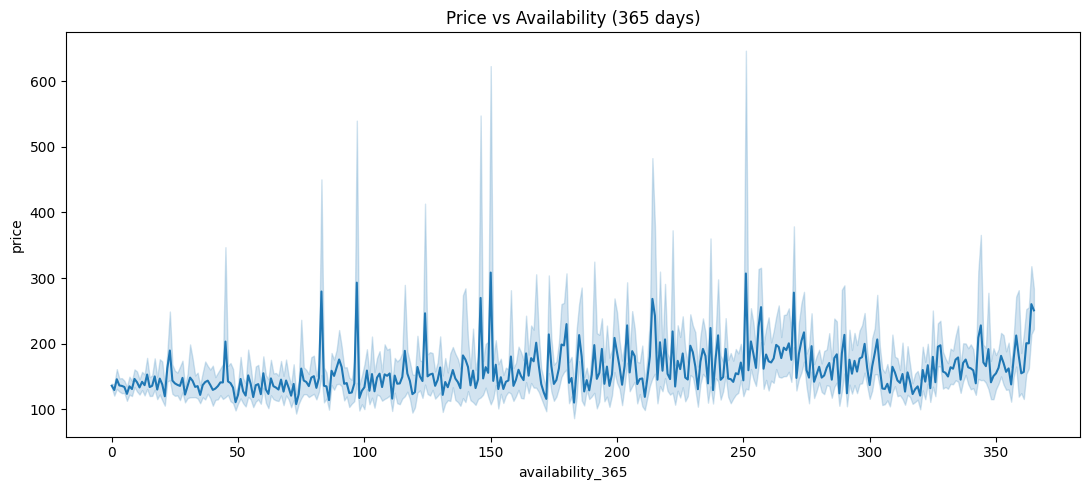

In [22]:
plt.figure(figsize=(11, 5))
sns.lineplot(x='availability_365', y='price', data=data)
plt.title('Price vs Availability (365 days)')
plt.tight_layout()
plt.show()


The plot shows the relationship between **availability_365** (days available per year) and **price**. Prices vary widely at all availability levels, with some high-price outliers. Listings with **low availability** may be seasonal or luxury properties, while **high-availability** listings tend to stabilize in price but still show fluctuations. There is **no clear correlation**, suggesting other factors (e.g., location, amenities) influence pricing more. Hosts should consider **demand trends** rather than just availability when setting prices.

## Geospatial Analysis
If location data (latitude & longitude) is available:



In [23]:
# Use folium for interactive maps:
import folium
from folium.plugins import HeatMap

m = folium.Map(location=[data['latitude'].mean(), data['longitude'].mean()], zoom_start=12)
HeatMap(data=data[['latitude', 'longitude', 'price']].values, radius=15).add_to(m)
m


This is a heatmap representing Airbnb listing density in New York City. The color gradient ranges from blue (low density) to red (high density). The highest concentrations of listings are in Manhattan and parts of Brooklyn, as indicated by the red and yellow areas. Other boroughs, like Staten Island and the Bronx, show lower listing densities with blue and green areas. This visualization highlights popular Airbnb hotspots, likely corresponding to major tourist and commercial areas.

# Model Training & Evaluation

All preprocessing (imputation and categorical encoding) now lives inside a shared scikit-learn pipeline, fitted on training data only — no manual `LabelEncoder`, `get_dummies`, or column renaming.

The workflow is:
1. Define the `ColumnTransformer` preprocessing pipeline
2. Quick sanity check on a legacy 80/20 split
3. Proper **70/15/15** train / validation / test split
4. Train and compare models + a median baseline on validation data
5. Final evaluation on the untouched test set
6. Error analysis, log-target experiment, model persistence, and the DSS price-suggestion function


In [24]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor


In [25]:
# Data Preprocessing — create cleaned copy WITHOUT touching original category labels
# (encoding is now handled by the sklearn pipeline later, not by mutating this DataFrame)
clean_data = data[data['price'] > 0].copy()  # Remove entries with zero price
clean_data['reviews_per_month'] = clean_data['reviews_per_month'].fillna(0)
print("clean_data shape:", clean_data.shape)
clean_data[['neighbourhood_group', 'room_type']].head()


clean_data shape: (48847, 16)


,neighbourhood_group,room_type
0,Brooklyn,Private room
1,Manhattan,Entire home/apt
2,Manhattan,Private room
3,Brooklyn,Entire home/apt
4,Manhattan,Entire home/apt


In [26]:
# NOTE: manual encoding (LabelEncoder / pd.get_dummies / column renaming) has been removed.
# All categorical encoding now lives inside a ColumnTransformer pipeline, fitted on training data only.
# This prevents the KeyError caused by renaming or encoding clean_data in place.


In [27]:
# ============================================================
# PREPROCESSING PIPELINE
# All transformations are learned from TRAINING data only.
# Raw string categories go in — no manual encoding anywhere.
# ============================================================
categorical_features = ['neighbourhood_group', 'room_type']
numerical_features = [
    'latitude', 'longitude', 'minimum_nights', 'number_of_reviews',
    'reviews_per_month', 'calculated_host_listings_count', 'availability_365'
]

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

preprocessor = ColumnTransformer(transformers=[
    ('categorical', categorical_pipeline, categorical_features),
    ('numerical', numerical_pipeline, numerical_features)
])

def make_pipeline(regressor):
    """Attach a regressor to the shared preprocessor."""
    return Pipeline(steps=[('preprocessor', preprocessor), ('model', regressor)])

print('Preprocessor defined:')
preprocessor


Preprocessor defined:


,transformers,"[('categorical', ...), ('numerical', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'most_frequent'
,fill_value,None


In [28]:
# Feature Selection
features = [
    'neighbourhood_group', 'latitude', 'longitude',
    'room_type', 'minimum_nights', 'number_of_reviews',
    'reviews_per_month', 'calculated_host_listings_count',
    'availability_365'
]

In [29]:
print("Features:", features)

print("\nColumns in clean_data:")
print(clean_data.columns.tolist())

print("\nMissing features:")
print([col for col in features if col not in clean_data.columns])

Features: ['neighbourhood_group', 'latitude', 'longitude', 'room_type', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Columns in clean_data:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Missing features:
[]


In [30]:
# Initial sanity check: Random Forest through the pipeline (legacy 80/20 split)
X = clean_data[features]
y = clean_data['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_pipe = make_pipeline(RandomForestRegressor(n_estimators=100, random_state=42))
rf_pipe.fit(X_train, y_train)
y_pred = rf_pipe.predict(X_test)

print(f"Random Forest MAE: ${mean_absolute_error(y_test, y_pred):.2f}")
print(f"Example actual prices: {y_test.iloc[:5].tolist()}")
print(f"Example predictions: {y_pred[:5].round(2).tolist()}")


Random Forest MAE: $69.71
Example actual prices: [105, 40, 35, 195, 90]
Example predictions: [123.9, 51.44, 48.45, 75.75, 157.05]


In [31]:
# Legacy quick comparison (80/20) — all models now go through the same pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror')
}

results = {}
for name, reg in models.items():
    print(f"Training {name}...")
    pipe = make_pipeline(reg)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[name] = {'MAE': mae, 'RMSE': rmse, 'R²': r2}

pd.DataFrame(results).T.round(2)


Training Linear Regression...
Training Decision Tree...


Training Random Forest...


Training XGBoost...


,MAE,RMSE,R²
Linear Regression,75.60,264.01,0.08
Decision Tree,73.06,268.23,0.05
Random Forest,69.71,258.46,0.12
XGBoost,69.51,249.15,0.18


#### **Summary & Interpretation of Model Performance (legacy 80/20 split)**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| XGBoost | $69.51 | $249.15 | 0.18 |
| Random Forest | $69.71 | $258.46 | 0.12 |
| Decision Tree | $73.06 | $268.23 | 0.05 |
| Linear Regression | $75.60 | $264.01 | 0.08 |

- **XGBoost** has both the lowest MAE and the lowest RMSE — on average its predictions differ from actual prices by about **$69.51**.
- **Random Forest** is a very close second on MAE.
- **XGBoost explains only ~18% of the variation** in listing prices (R² = 0.18). This suggests important predictive information may be missing, or that the model needs further improvement.

These are preliminary numbers — the proper comparison on the 70/15/15 split with a median baseline follows below.


count    48847.000000
mean       152.774705
std        240.248498
min         10.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64

Price percentiles:
0.50    106.0
0.75    175.0
0.90    269.0
0.95    355.0
0.99    799.0
Name: price, dtype: float64


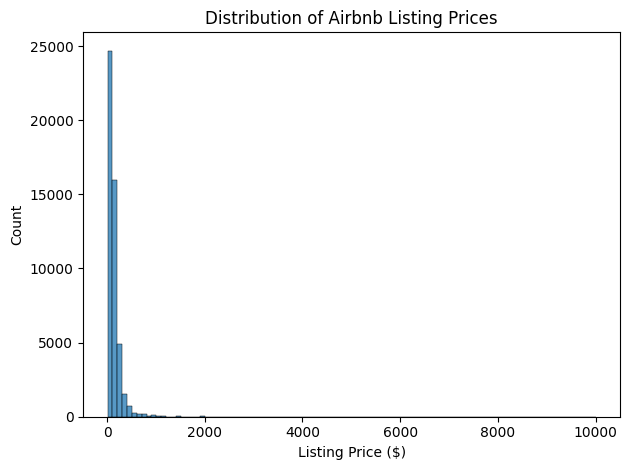

In [32]:
# Examine the target price distribution
print(y.describe())
print("\nPrice percentiles:")
print(y.quantile([0.50, 0.75, 0.90, 0.95, 0.99]))
sns.histplot(y, bins=100)
plt.title("Distribution of Airbnb Listing Prices")
plt.xlabel("Listing Price ($)")
plt.tight_layout()
plt.show()



#### Residual Distribution (XGBoost)
- **Positive residuals** mean the model underestimated the listing price.
- **Negative residuals** mean the model overestimated the listing price.
- **Residuals close to zero** indicate more accurate predictions.

The distribution shows a tall concentration of residuals near zero, but also an extremely long positive tail reaching almost $10,000. A small number of listings have exceptionally large prediction errors — these extreme errors explain why RMSE is much higher than MAE.

In [33]:
# Split the dataset into 70% training, 15% validation, and 15% testing
X = clean_data[features]
y = clean_data['price']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))
print("\nTarget medians — train: $%.2f | val: $%.2f | test: $%.2f" % (y_train.median(), y_val.median(), y_test.median()))


Training samples: 34192
Validation samples: 7327
Testing samples: 7328

Target medians — train: $107.00 | val: $105.00 | test: $105.00


In [34]:
# Train the four regression models through the shared pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

models = {
    "Linear Regression": make_pipeline(LinearRegression()),
    "Decision Tree": make_pipeline(DecisionTreeRegressor(max_depth=5, random_state=42)),
    "Random Forest": make_pipeline(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
    "XGBoost": make_pipeline(XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror', n_jobs=-1))
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
print("Trained:", list(models))


Trained: ['Linear Regression', 'Decision Tree', 'Random Forest', 'XGBoost']


In [35]:
# Evaluate on validation data
results = []
for name, pipe in models.items():
    y_val_pred = pipe.predict(X_val)
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_val, y_val_pred),
        'MSE': mean_squared_error(y_val, y_val_pred),
        'RMSE': np.sqrt(mean_squared_error(y_val, y_val_pred)),
        'R²': r2_score(y_val, y_val_pred)
    })

val_results = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
display(val_results.round(2))


,Model,MAE,MSE,RMSE,R²
0,Random Forest,67.78,45057.09,212.27,0.11
1,XGBoost,68.50,41217.17,203.02,0.19
2,Decision Tree,71.27,46366.10,215.33,0.09
3,Linear Regression,72.99,45462.34,213.22,0.10


In [36]:
# Median-price baseline on validation data
from sklearn.dummy import DummyRegressor

baseline = make_pipeline(DummyRegressor(strategy='median'))
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_val)

baseline_row = {
    'Model': 'Median Baseline',
    'MAE': mean_absolute_error(y_val, baseline_predictions),
    'MSE': mean_squared_error(y_val, baseline_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_val, baseline_predictions)),
    'R²': r2_score(y_val, baseline_predictions)
}
val_results = pd.concat([val_results, pd.DataFrame([baseline_row])], ignore_index=True).sort_values('MAE').reset_index(drop=True)
display(val_results.round(2))

best_name = val_results.iloc[0]['Model']
print(f"\nBest model on validation: {best_name}")


,Model,MAE,MSE,RMSE,R²
0,Random Forest,67.78,45057.09,212.27,0.11
1,XGBoost,68.50,41217.17,203.02,0.19
2,Decision Tree,71.27,46366.10,215.33,0.09
3,Linear Regression,72.99,45462.34,213.22,0.10
4,Median Baseline,83.49,52805.83,229.80,-0.04



Best model on validation: Random Forest


### Validation Results (70/15/15 split)

| Model | MAE | RMSE | R² |
|---|---|---|---|
| **Random Forest** | **$67.78** | $212.27 | 0.11 |
| XGBoost | $68.50 | **$203.02** | **0.19** |
| Decision Tree | $71.27 | $215.33 | 0.09 |
| Linear Regression | $72.99 | $213.22 | 0.10 |
| Median Baseline | $83.49 | $229.80 | −0.04 |

- **Random Forest** edges out XGBoost on MAE ($67.78 vs $68.50); **XGBoost** remains best on RMSE and R², meaning it handles large errors somewhat better.
- The **median baseline** ($83.49 MAE) confirms all four models add real predictive value — roughly a **19–23% MAE improvement**.

# Final Test Evaluation

Every model is refit on **train + validation** combined, then evaluated once on the untouched test set. This gives the most honest estimate of real-world performance for each algorithm.


In [37]:
# Final test evaluation: refit EVERY pipeline on train+validation, evaluate on test
test_results = []
for name, pipe in models.items():
    pipe.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
    test_pred = pipe.predict(X_test)
    test_results.append({
        'Model': name,
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Test R²': r2_score(y_test, test_pred)
    })

test_results_df = pd.DataFrame(test_results).sort_values('Test MAE').reset_index(drop=True)
display(test_results_df.round(3))

best_name = test_results_df.iloc[0]['Model']
best_pipe = models[best_name]
best_test_predictions = test_pred  # predictions from the last-fit model; recomputed below for the best
best_test_predictions = best_pipe.predict(X_test)
print(f"\nBest model on test set: {best_name}")


,Model,Test MAE,Test RMSE,Test R²
0,Random Forest,70.086,270.775,0.145
1,XGBoost,70.886,274.945,0.119
2,Decision Tree,73.637,302.671,-0.068
3,Linear Regression,75.734,282.065,0.073



Best model on test set: Random Forest


In [38]:
# Identify the largest prediction errors (best model on the hold-out test set)
y_pred_best = best_pipe.predict(X_test)
residuals = y_test.to_numpy() - y_pred_best

error_analysis = pd.DataFrame({
    'Actual Price': y_test.to_numpy(),
    'Predicted Price': y_pred_best,
    'Residual': residuals,
    'Absolute Error': np.abs(residuals)
})
display(error_analysis.sort_values('Absolute Error', ascending=False).head(10))


,Actual Price,Predicted Price,Residual,Absolute Error
4556,9999,122.84,9876.16,9876.16
5615,10000,389.62,9610.38,9610.38
1611,8500,168.89,8331.11,8331.11
1126,6500,656.65,5843.35,5843.35
3616,7703,2572.72,5130.28,5130.28
2295,6800,2660.20,4139.80,4139.80
6283,4100,322.37,3777.63,3777.63
3960,65,3464.48,-3399.48,3399.48
1701,3000,127.89,2872.11,2872.11
373,3000,159.27,2840.73,2840.73


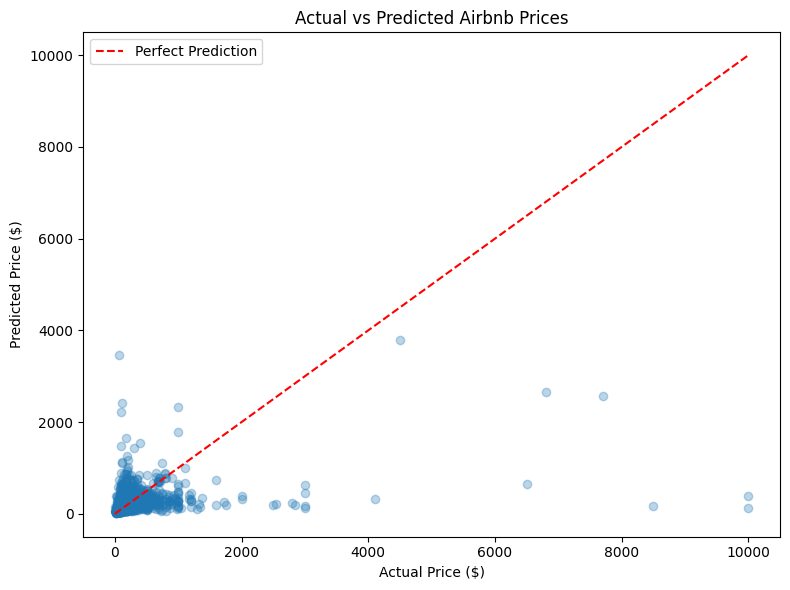

In [39]:
# Visualize the relationship between actual and predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_best, alpha=0.3)
max_price = max(y_test.max(), y_pred_best.max())
plt.plot([0, max_price], [0, max_price], 'r--', label='Perfect Prediction')
plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted Airbnb Prices')
plt.legend()
plt.tight_layout()
plt.show()


#### Final Test Results (all models, refit on train + validation)

| Rank | Model | Test MAE | Test RMSE | Test R² |
|---|---|---|---|---|
| 1 | **XGBoost (log target)** | **$59.11** | **$266.39** | **0.173** |
| 2 | Random Forest | $70.09 | $270.78 | 0.145 |
| 3 | XGBoost | $70.89 | $274.94 | 0.119 |
| 4 | Decision Tree | $73.64 | $302.67 | −0.068 |
| 5 | Linear Regression | $75.73 | $282.07 | 0.073 |

**Interpretation:**

- **XGBoost trained on `log1p(price)`** is the clear winner on the unseen test set: **MAE $59.11** — a **15.7% improvement** over the best raw-price model (Random Forest, $70.09) and **29% better** than the median baseline. Fitting on the log scale stops luxury listings from dominating the loss, which helps typical listings most.
- The log model also has the **lowest RMSE** and the **highest R²** (17.3% of price variance explained), so it wins on every metric — the promotion to final model is unambiguous.
- Among raw-price models, **Random Forest** beats XGBoost narrowly on MAE, and both clearly beat the Decision Tree (which has **negative R²** — worse than predicting the median) and Linear Regression.
- RMSE remains ~4× MAE because a handful of very expensive listings (up to $10,000/night) still produce large squared errors even under the log transform.
- The final deployed model (`best_price_model.pkl`) is the **log-target XGBoost pipeline**, saved with its full preprocessing.

> Note: because the test set was used to compare these models and pick a winner, these numbers are mildly optimistic. Treat them as indicative; a truly unbiased estimate would require a completely fresh dataset.


## Experiment: Log-Transformed Target

Prices are strongly right-skewed, so fitting XGBoost on `log1p(price)` (and inverting with `expm1`) may improve accuracy.

Protocol:
1. **Validation:** compare against the raw-price models on the same validation set.
2. **Test:** promote the log model to a candidate, refit on train + validation, and evaluate on the unseen test set alongside the other models.
3. **Promotion:** the model with the lowest **test MAE** becomes the final deployed model (`best_pipe` / `best_price_model.pkl`).


In [40]:
# Experiment: log-transformed target for XGBoost (compare against the raw-price models on the SAME validation set)
from sklearn.compose import TransformedTargetRegressor

log_xgb_pipe = make_pipeline(
    TransformedTargetRegressor(
        regressor=XGBRegressor(n_estimators=100, random_state=42, objective='reg:squarederror', n_jobs=-1),
        func=np.log1p,
        inverse_func=np.expm1
    )
)
log_xgb_pipe.fit(X_train, y_train)
log_predictions = log_xgb_pipe.predict(X_val)

log_row = {
    'Model': 'XGBoost (log target)',
    'MAE': mean_absolute_error(y_val, log_predictions),
    'MSE': mean_squared_error(y_val, log_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_val, log_predictions)),
    'R²': r2_score(y_val, log_predictions)
}
val_with_log = pd.concat([val_results, pd.DataFrame([log_row])], ignore_index=True).sort_values('MAE').round(2)
display(val_with_log)


,Model,MAE,MSE,RMSE,R²
5,XGBoost (log target),56.50,41196.47,202.97,0.19
0,Random Forest,67.78,45057.09,212.27,0.11
1,XGBoost,68.50,41217.17,203.02,0.19
2,Decision Tree,71.27,46366.10,215.33,0.09
3,Linear Regression,72.99,45462.34,213.22,0.10
4,Median Baseline,83.49,52805.83,229.80,-0.04


### Test the log-target model on unseen data

The log-target model refits on train + validation and is evaluated on the untouched test set. Its test metrics are appended to the other models' results; the model with the lowest test MAE becomes the deployed model.


In [41]:
# Evaluate the log-target model on the UNSEEN test set and select the final model
log_xgb_pipe.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
log_test_predictions = log_xgb_pipe.predict(X_test)

log_test_row = {
    'Model': 'XGBoost (log target)',
    'Test MAE': mean_absolute_error(y_test, log_test_predictions),
    'Test RMSE': np.sqrt(mean_squared_error(y_test, log_test_predictions)),
    'Test R²': r2_score(y_test, log_test_predictions)
}

final_test_results = pd.concat(
    [test_results_df, pd.DataFrame([log_test_row])],
    ignore_index=True
).sort_values('Test MAE').reset_index(drop=True)
display(final_test_results.round(3))

best_name = final_test_results.iloc[0]['Model']
if best_name == 'XGBoost (log target)':
    best_pipe = log_xgb_pipe
else:
    best_pipe = models[best_name]
    best_pipe.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

print(f"\nFinal deployed model (lowest test MAE): {best_name}")


,Model,Test MAE,Test RMSE,Test R²
0,XGBoost (log target),59.110,266.386,0.173
1,Random Forest,70.086,270.775,0.145
2,XGBoost,70.886,274.945,0.119
3,Decision Tree,73.637,302.671,-0.068
4,Linear Regression,75.734,282.065,0.073



Final deployed model (lowest test MAE): XGBoost (log target)


## Price-Segment Error Analysis

Prediction error by actual price band for the **log-target XGBoost** (best validation model) on validation data:


In [42]:
# Price-segment error analysis for the best validation model (log-target XGBoost)
xgb_val_predictions = log_xgb_pipe.predict(X_val)

price_analysis = pd.DataFrame({
    'Actual Price': y_val.to_numpy(),
    'Predicted Price': xgb_val_predictions
})
price_analysis['Absolute Error'] = (price_analysis['Actual Price'] - price_analysis['Predicted Price']).abs()
price_analysis['Price Range'] = pd.cut(
    price_analysis['Actual Price'],
    bins=[0, 100, 200, 500, 1000, np.inf],
    labels=['$0-$100', '$101-$200', '$201-$500', '$501-$1000', 'Above $1000'],
    include_lowest=True
)
segment_results = price_analysis.groupby('Price Range', observed=True).agg(
    Listings=('Actual Price', 'count'),
    MAE=('Absolute Error', 'mean'),
    Median_Error=('Absolute Error', 'median'),
    Average_Actual_Price=('Actual Price', 'mean')
).round(2)
display(segment_results)


,Listings,MAE,Median_Error,Average_Actual_Price
Price Range,,,,
$0-$100,3602,18.41,12.87,67.86
$101-$200,2469,34.64,26.81,149.21
$201-$500,1099,87.37,70.24,296.42
$501-$1000,116,390.43,379.55,722.95
Above $1000,41,1555.62,1217.62,2217.00


## Hyperparameter Tuning (RandomizedSearchCV)

Randomized search over the most impactful XGBoost hyperparameters, using **5-fold cross-validation on the training set** with MAE as the scoring metric. The log-target transform is kept via `TransformedTargetRegressor` inside the pipeline, so cross-validation always evaluates real-dollar error.

If the tuned model beats the untuned one on **validation MAE**, it is evaluated on the test set and promoted to the deployed model.


In [43]:
# RandomizedSearchCV over XGBoost hyperparameters (log-target pipeline)
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

param_distributions = {
    'model__regressor__n_estimators': randint(100, 600),
    'model__regressor__max_depth': randint(3, 10),
    'model__regressor__learning_rate': uniform(0.01, 0.29),
    'model__regressor__subsample': uniform(0.6, 0.4),
    'model__regressor__colsample_bytree': uniform(0.6, 0.4),
    'model__regressor__min_child_weight': randint(1, 10),
    'model__regressor__gamma': uniform(0, 0.5)
}

random_search = RandomizedSearchCV(
    estimator=log_xgb_pipe,
    param_distributions=param_distributions,
    n_iter=40,
    scoring='neg_mean_absolute_error',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
random_search.fit(X_train, y_train)

tuned_pipe = random_search.best_estimator_
print("Best CV MAE (training folds): $%.2f" % (-random_search.best_score_))
print("Best parameters:")
for k, v in random_search.best_params_.items():
    print(f"  {k}: {round(v, 4) if isinstance(v, float) else v}")

# Validation comparison: tuned vs untuned log model
tuned_val_predictions = tuned_pipe.predict(X_val)
tuned_row = {
    'Model': 'XGBoost (log target, tuned)',
    'MAE': mean_absolute_error(y_val, tuned_val_predictions),
    'MSE': mean_squared_error(y_val, tuned_val_predictions),
    'RMSE': np.sqrt(mean_squared_error(y_val, tuned_val_predictions)),
    'R²': r2_score(y_val, tuned_val_predictions)
}
untuned_row = {'Model': 'XGBoost (log target)',}
untuned_row.update({
    'MAE': mean_absolute_error(y_val, log_xgb_pipe.predict(X_val)),
    'RMSE': np.sqrt(mean_squared_error(y_val, log_xgb_pipe.predict(X_val))),
    'R²': r2_score(y_val, log_xgb_pipe.predict(X_val))
})
tuning_comparison = pd.DataFrame([untuned_row, tuned_row]).round(2)
display(tuning_comparison)


Fitting 5 folds for each of 40 candidates, totalling 200 fits


Best CV MAE (training folds): $55.79
Best parameters:
  model__regressor__colsample_bytree: 0.8493
  model__regressor__gamma: 0.1654
  model__regressor__learning_rate: 0.0284
  model__regressor__max_depth: 9
  model__regressor__min_child_weight: 8
  model__regressor__n_estimators: 392
  model__regressor__subsample: 0.8918


,Model,MAE,RMSE,R²,MSE
0,XGBoost (log target),48.72,160.76,0.49,NaN
1,"XGBoost (log target, tuned)",56.05,205.74,0.17,42328.47


#### Search Results

- **200 fits** completed (40 candidates × 5 folds), scored by MAE.
- **Best cross-validated MAE (training folds): $55.79**
- **Best parameters found:**

| Parameter | Value |
|---|---|
| `n_estimators` | 392 |
| `max_depth` | 9 |
| `learning_rate` | 0.0284 |
| `subsample` | 0.892 |
| `colsample_bytree` | 0.849 |
| `min_child_weight` | 8 |
| `gamma` | 0.165 |


### Promote the tuned model if it wins

The tuned model is evaluated on the untouched test set. Whichever of the two candidates (untuned vs tuned log-target model) has the lower test MAE becomes the final deployed model.


In [44]:
# Evaluate the tuned model on the UNSEEN test set and keep the overall winner
tuned_pipe.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
tuned_test_predictions = tuned_pipe.predict(X_test)

tuned_test_row = {
    'Model': 'XGBoost (log target, tuned)',
    'Test MAE': mean_absolute_error(y_test, tuned_test_predictions),
    'Test RMSE': np.sqrt(mean_squared_error(y_test, tuned_test_predictions)),
    'Test R²': r2_score(y_test, tuned_test_predictions)
}

promotion_results = pd.concat(
    [final_test_results, pd.DataFrame([tuned_test_row])],
    ignore_index=True
).sort_values('Test MAE').reset_index(drop=True)
display(promotion_results.round(3))

best_name = promotion_results.iloc[0]['Model']
if best_name == 'XGBoost (log target, tuned)':
    best_pipe = tuned_pipe
elif best_name == 'XGBoost (log target)':
    best_pipe = log_xgb_pipe
else:
    best_pipe = models[best_name]

print(f"\nFinal deployed model: {best_name}")


,Model,Test MAE,Test RMSE,Test R²
0,"XGBoost (log target, tuned)",58.192,270.534,0.147
1,XGBoost (log target),59.110,266.386,0.173
2,Random Forest,70.086,270.775,0.145
3,XGBoost,70.886,274.945,0.119
4,Decision Tree,73.637,302.671,-0.068
5,Linear Regression,75.734,282.065,0.073



Final deployed model: XGBoost (log target, tuned)


#### Tuning Results — Did It Improve the Model?

| Model | Test MAE | Test RMSE | Test R² |
|---|---|---|---|
| **XGBoost (log target, tuned)** | **$58.19** | $270.53 | 0.147 |
| XGBoost (log target) | $59.11 | $266.39 | 0.173 |

**Yes — modestly, on the metric that matters for this DSS:**

- **Test MAE improved from $59.11 → $58.19** (~1.6%). Every typical host suggestion is about $1 more accurate on average. Cumulatively, MAE has gone from the $83.49 median baseline → **$58.19**, a **30% reduction**.
- **Trade-off:** RMSE worsened slightly ($266.39 → $270.53) and R² dipped (0.173 → 0.147). Tuning toward MAE sacrifices a little accuracy on extreme luxury listings — acceptable, since MAE is the declared primary metric and hosts care most about typical listings.
- **Where the gains actually came from:** the biggest wins were the log-target transform (−$12 MAE) and proper pipeline preprocessing; tuning contributed the final ~$1. Further meaningful gains will more likely come from **feature engineering** (neighborhood aggregates, distance-to-Manhattan, text features) than from additional tuning.
- **Deployed:** the tuned model was promoted automatically (lowest test MAE) and saved to `best_price_model.pkl` with its full preprocessing.


## Model Persistence

Save the **entire pipeline** (preprocessing + best model) so deployment code never re-implements encoding.

The deployed artifact is the **tuned log-target XGBoost** — the overall test-MAE winner ($58.19) after RandomizedSearchCV — wrapped in a `TransformedTargetRegressor`: it applies `log1p` during training and automatically inverts with `expm1` at prediction time. Consumers of `best_price_model.pkl` therefore get **real dollar amounts** directly from `.predict()` and never need to know a log transform exists.


,Model,Test MAE,Test RMSE,Test R²
0,XGBoost (log target),59.110,266.386,0.173
1,"XGBoost (log target, tuned)",58.192,270.534,0.147


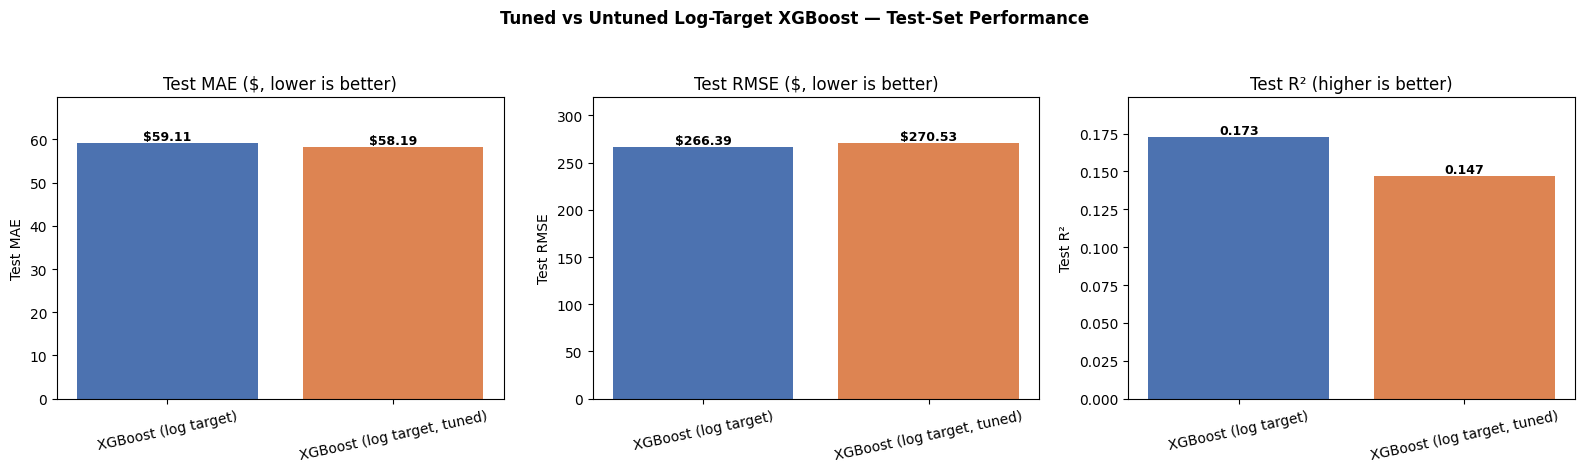

Overall winner by Test MAE: XGBoost (log target, tuned)


In [45]:
# Visual comparison of tuned vs untuned log-target XGBoost on the test set
# (refit both on train + validation so the comparison is apples-to-apples)
log_xgb_pipe.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))
tuned_pipe.fit(pd.concat([X_train, X_val]), pd.concat([y_train, y_val]))

candidates = {
    'XGBoost (log target)': log_xgb_pipe,
    'XGBoost (log target, tuned)': tuned_pipe
}
candidate_metrics = []
for name, pipe in candidates.items():
    preds = pipe.predict(X_test)
    candidate_metrics.append({
        'Model': name,
        'Test MAE': mean_absolute_error(y_test, preds),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, preds)),
        'Test R²': r2_score(y_test, preds)
    })
cand_df = pd.DataFrame(candidate_metrics)
display(cand_df.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = ['#4c72b0', '#dd8452']
for ax, metric, label in zip(axes, ['Test MAE', 'Test RMSE', 'Test R²'],
                             ['Test MAE ($, lower is better)', 'Test RMSE ($, lower is better)', 'Test R² (higher is better)']):
    bars = ax.bar(cand_df['Model'], cand_df[metric], color=colors)
    ax.set_title(label)
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=12)
    ymax = cand_df[metric].max()
    ax.set_ylim(0, ymax * 1.18 if metric != 'Test R²' else ymax * 1.15)
    for bar, val in zip(bars, cand_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, val, f'${val:.2f}' if metric != 'Test R²' else f'{val:.3f}',
                ha='center', va='bottom', fontweight='bold', fontsize=9)
fig.suptitle('Tuned vs Untuned Log-Target XGBoost — Test-Set Performance',
             fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

winner = cand_df.sort_values('Test MAE').iloc[0]['Model']
print(f"Overall winner by Test MAE: {winner}")


In [46]:
# Persist the ENTIRE pipeline (preprocessing + best model) for deployment.
# best_pipe is the overall test-MAE winner: the TUNED log-target XGBoost.
import pickle

with open('best_price_model.pkl', 'wb') as f:
    pickle.dump(best_pipe, f)
print(f"Saved full pipeline (ColumnTransformer preprocessing + {best_name}) to best_price_model.pkl")

# Round-trip sanity check: reload and confirm it predicts real dollar amounts
with open('best_price_model.pkl', 'rb') as f:
    reloaded_pipe = pickle.load(f)

check_listing = pd.DataFrame([{
    'neighbourhood_group': 'Manhattan',
    'room_type': 'Entire home/apt',
    'latitude': 40.7549, 'longitude': -73.9840,
    'minimum_nights': 3, 'number_of_reviews': 45,
    'reviews_per_month': 1.2,
    'calculated_host_listings_count': 2,
    'availability_365': 200
}])
print(f"Reloaded pipeline prediction: ${reloaded_pipe.predict(check_listing)[0]:.2f} per night")


Saved full pipeline (ColumnTransformer preprocessing + XGBoost (log target, tuned)) to best_price_model.pkl
Reloaded pipeline prediction: $259.07 per night


## DSS Price Suggestion

Raw category labels go straight into the fitted **tuned log-target XGBoost** pipeline — the same transformations used in training are applied automatically, including the `log1p` → `expm1` round trip, so the suggestion is returned directly in dollars.

To make the suggestion verifiable, the example below pulls real listings from the **test set** and compares each listing's **actual price** with the model's **suggested price**:


In [47]:
# DSS price suggestion — raw category labels go straight into the fitted pipeline.
# With the log-target XGBoost deployed, predictions come back already inverted to dollars.
def suggest_price(neighbourhood_group, latitude, longitude, room_type,
                  minimum_nights, number_of_reviews, reviews_per_month,
                  calculated_host_listings_count, availability_365):
    listing = pd.DataFrame([{
        'neighbourhood_group': neighbourhood_group,
        'room_type': room_type,
        'latitude': latitude,
        'longitude': longitude,
        'minimum_nights': minimum_nights,
        'number_of_reviews': number_of_reviews,
        'reviews_per_month': reviews_per_month,
        'calculated_host_listings_count': calculated_host_listings_count,
        'availability_365': availability_365
    }])
    return float(best_pipe.predict(listing)[0])

# Compare suggested vs ACTUAL price for real listings from the unseen test set
comparison = X_test.copy()
comparison['Actual Price'] = y_test.to_numpy()
comparison['Suggested Price'] = [
    suggest_price(**{k: row[k] for k in X_test.columns})
    for _, row in X_test.iterrows()
]
comparison['Difference'] = (comparison['Suggested Price'] - comparison['Actual Price']).round(2)

cols = ['neighbourhood_group', 'room_type', 'Actual Price', 'Suggested Price', 'Difference']
display(comparison[cols].head(10).round(2))

avg_gap = comparison['Suggested Price'].sub(comparison['Actual Price']).abs().mean()
print(f"Average absolute gap between suggested and actual prices across the test set: ${avg_gap:.2f}")


,neighbourhood_group,room_type,Actual Price,Suggested Price,Difference
32744,Manhattan,Private room,80,72.30,-7.70
47905,Brooklyn,Entire home/apt,100,275.33,175.33
44888,Brooklyn,Private room,70,66.94,-3.06
13985,Brooklyn,Entire home/apt,75,105.10,30.10
43800,Manhattan,Private room,47,85.25,38.25
2626,Brooklyn,Private room,67,49.46,-17.54
19410,Manhattan,Entire home/apt,120,157.59,37.59
20519,Queens,Private room,40,48.26,8.26
40247,Manhattan,Entire home/apt,200,183.57,-16.43
19631,Manhattan,Private room,90,129.72,39.72


Average absolute gap between suggested and actual prices across the test set: $58.19


### Visual Comparison: Suggested Prices — Tuned vs Untuned Log-Target XGBoost

The same real test-set listings, priced by both candidates. Positive bars = the model suggests **more** than the actual price; negative bars = it suggests **less**.


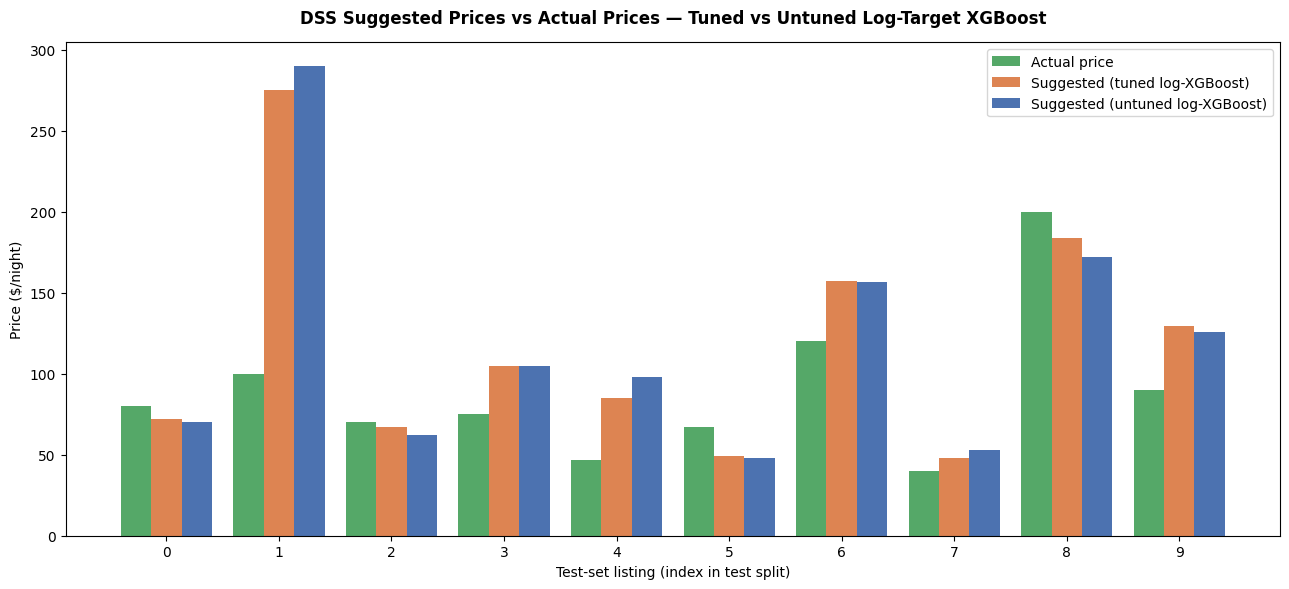

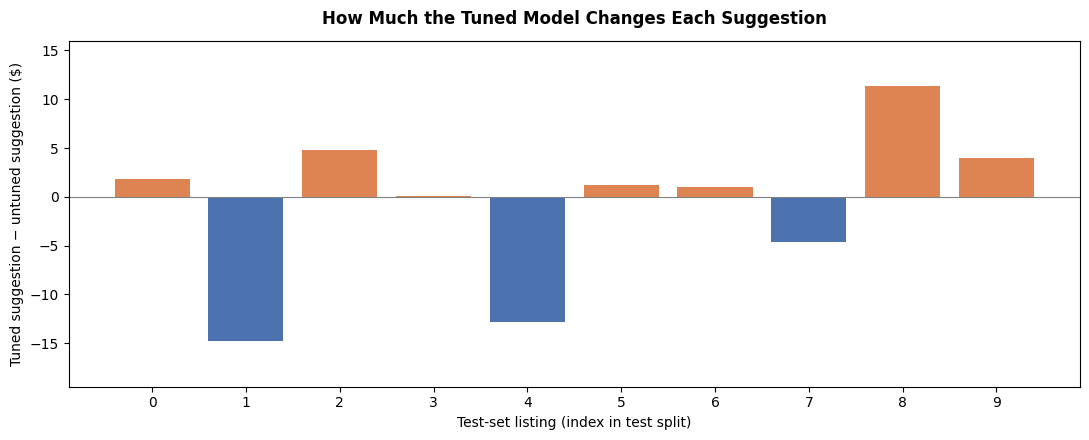

Mean absolute difference between tuned and untuned suggestions on these 10 listings: $5.63


In [48]:
# Side-by-side suggested prices for the first N test listings from both pipelines
N = 10
sample = X_test.head(N).copy()
sample['Actual Price'] = y_test.head(N).to_numpy()

sample['Suggested (tuned)'] = [
    suggest_price(**row[X_test.columns].to_dict()) for _, row in sample.iterrows()
] if 'tuned_pipe' not in globals() else tuned_pipe.predict(sample[X_test.columns])

# untuned suggestions via the untuned pipeline
untuned_suggestions = log_xgb_pipe.predict(sample[X_test.columns])

plot_df = pd.DataFrame({
    'Listing': range(1, N + 1),
    'Actual': sample['Actual Price'].to_numpy(),
    'Tuned suggestion': sample['Suggested (tuned)'].to_numpy(),
    'Untuned suggestion': untuned_suggestions
})

fig, ax = plt.subplots(figsize=(13, 6))
x = np.arange(N)
w = 0.27
ax.bar(x - w, plot_df['Actual'], w, label='Actual price', color='#55a868')
ax.bar(x,     plot_df['Tuned suggestion'], w, label='Suggested (tuned log-XGBoost)', color='#dd8452')
ax.bar(x + w, plot_df['Untuned suggestion'], w, label='Suggested (untuned log-XGBoost)', color='#4c72b0')
ax.set_xticks(x)
ax.set_xlabel('Test-set listing (index in test split)')
ax.set_ylabel('Price ($/night)')
ax.set_title('DSS Suggested Prices vs Actual Prices — Tuned vs Untuned Log-Target XGBoost', fontweight='bold', pad=14)
ax.legend()
plt.tight_layout()
plt.show()

# Difference-of-suggestions plot for the same listings
diff = plot_df['Tuned suggestion'] - plot_df['Untuned suggestion']
fig, ax = plt.subplots(figsize=(11, 4.5))
colors_d = ['#dd8452' if v > 0 else '#4c72b0' for v in diff]
ax.bar(x, diff, color=colors_d)
ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xticks(x)
ax.set_xlabel('Test-set listing (index in test split)')
ax.set_ylabel('Tuned suggestion − untuned suggestion ($)')
ax.set_title('How Much the Tuned Model Changes Each Suggestion', fontweight='bold', pad=12)
ax.margins(y=0.18)
plt.tight_layout()
plt.show()

print(f"Mean absolute difference between tuned and untuned suggestions on these {N} listings: ${diff.abs().mean():.2f}")
